In [1]:

import pandas as pd
import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, "electricity.zip")

print("Download completed!")

with zipfile.ZipFile("electricity.zip", "r") as z:
    with z.open("household_power_consumption.txt") as f:
        df = pd.read_csv(
            f,
            sep=";",
            nrows=10000,
            na_values=["?"],
            low_memory=False
        )

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())


Download completed!
Dataset loaded successfully!
Shape: (10000, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [2]:

# Check missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert measurement columns into numeric values
cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing values
df[cols] = df[cols].ffill().bfill()

# Check again
print("\nMissing values after cleaning:")
print(df[cols].isnull().sum())

print("\nDataset shape:", df.shape)


Missing values before cleaning:
Date                     0
Time                     0
Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
Sub_metering_1           2
Sub_metering_2           2
Sub_metering_3           2
dtype: int64

Missing values after cleaning:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Dataset shape: (10000, 9)


In [3]:

from sklearn.preprocessing import MinMaxScaler

# Select electricity consumption
data = df[["Global_active_power"]].values

# Normalize values between 0 and 1
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

print("Original values:")
print(data[:5])

print("\nNormalized values:")
print(scaled_data[:5])


Original values:
[[4.216]
 [5.36 ]
 [5.374]
 [5.388]
 [3.666]]

Normalized values:
[[0.52301691]
 [0.67178153]
 [0.67360208]
 [0.67542263]
 [0.45149545]]


In [4]:

import numpy as np

# Number of previous minutes to consider
time_steps = 60

X = []
y = []

# Create sequences
for i in range(time_steps, len(scaled_data)):
    X.append(scaled_data[i-time_steps:i, 0])
    y.append(scaled_data[i, 0])

# Convert lists into NumPy arrays
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Sequence creation completed!")


X shape: (9940, 60)
y shape: (9940,)
Sequence creation completed!


In [5]:

split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# Reshape for LSTM:
# samples, time steps, features
X_train = X_train.reshape(X_train.shape[0], 60, 1)
X_test = X_test.reshape(X_test.shape[0], 60, 1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (7952, 60, 1)
X_test: (1988, 60, 1)
y_train: (7952,)
y_test: (1988,)


In [6]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Build the LSTM model
model = Sequential([
    LSTM(50, return_sequences=True,
         input_shape=(60, 1)),

    Dropout(0.2),

    LSTM(50),

    Dropout(0.2),

    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model structure
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop]
)


Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - loss: 0.0123 - val_loss: 0.0030
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - loss: 0.0061 - val_loss: 0.0023
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - loss: 0.0055 - val_loss: 0.0019
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - loss: 0.0053 - val_loss: 0.0017
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - loss: 0.0049 - val_loss: 0.0016
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - loss: 0.0049 - val_loss: 0.0015
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - loss: 0.0047 - val_loss: 0.0015
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - loss: 0.0046 - val_loss: 0.0014
Epoch 9/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - loss: 0.0045 - val_loss: 0.0013
Epoch 10/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - loss: 0.0044 - val_loss: 0.0012


In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict electricity consumption
predicted = model.predict(X_test)

# Convert normalized values back to original kW values
actual_power = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

predicted_power = scaler.inverse_transform(predicted)

# Calculate MAE and RMSE
mae = mean_absolute_error(actual_power, predicted_power)

rmse = np.sqrt(
    mean_squared_error(actual_power, predicted_power)
)

print("MAE:", round(mae, 4), "kW")
print("RMSE:", round(rmse, 4), "kW")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
MAE: 0.5436 kW
RMSE: 0.7672 kW


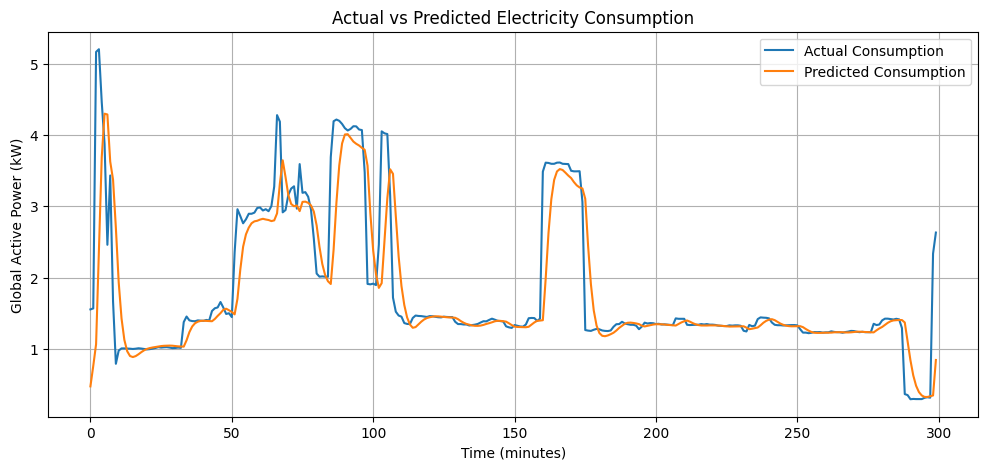

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actual_power[:300],
    label="Actual Consumption"
)

plt.plot(
    predicted_power[:300],
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Time (minutes)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)

plt.show()


In [10]:

results = pd.DataFrame({
    "Actual Power (kW)": actual_power.flatten()[:10],
    "Predicted Power (kW)": predicted_power.flatten()[:10]
})

print(results.round(3))


   Actual Power (kW)  Predicted Power (kW)
0              1.552                 0.471
1              1.566                 0.757
2              5.170                 1.063
3              5.208                 2.366
4              4.466                 3.689
5              3.878                 4.302
6              2.460                 4.291
7              3.434                 3.629
8              1.664                 3.376
9              0.788                 2.697


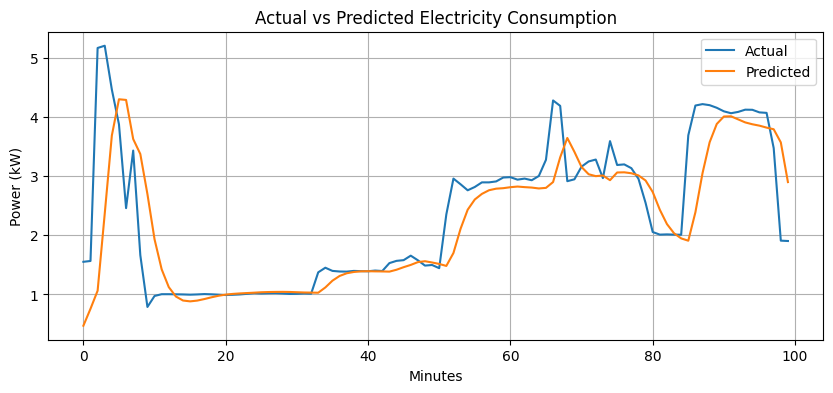

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(actual_power[:100], label="Actual")
plt.plot(predicted_power[:100], label="Predicted")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Minutes")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid()
plt.show()


In [12]:

# Check whether model training is completed
if "history" in globals() and "model" in globals():
    print("Training: COMPLETED")

    # Test the model on unseen test data
    test_loss = model.evaluate(X_test, y_test, verbose=0)

    print("Testing: COMPLETED")
    print("Test Loss:", round(test_loss, 4))

    # Generate predictions
    predictions = model.predict(X_test[:5], verbose=0)

    print("Prediction: SUCCESSFUL")
    print("First 5 predicted normalized values:")
    print(predictions.flatten())

else:
    print("Training is not completed yet.")


Training: COMPLETED
Testing: COMPLETED
Test Loss: 0.01
Prediction: SUCCESSFUL
First 5 predicted normalized values:
[0.03596205 0.07323758 0.11296903 0.28239438 0.45446542]


In [13]:
# Test the trained LSTM model with one example

# Take the first sample from test data
sample = X_test[0:1]

# Predict electricity consumption
prediction = model.predict(sample, verbose=0)

# Convert normalized prediction back to kW
predicted_value = scaler.inverse_transform(prediction)[0][0]

# Get the actual electricity consumption
actual_value = scaler.inverse_transform(
    y_test[0:1].reshape(-1, 1)
)[0][0]

print("Actual Electricity Consumption:", round(actual_value, 3), "kW")
print("Predicted Electricity Consumption:", round(predicted_value, 3), "kW")
print("LSTM Testing Successful!")

Actual Electricity Consumption: 1.552 kW
Predicted Electricity Consumption: 0.471 kW
LSTM Testing Successful!
